# TP2 — Partie 1 : ACP

## Introduction générale

L’analyse en composantes principales (ACP) réduit la dimension d’un jeu de données en construisant des axes orthogonaux qui résument, dans l’ordre, le maximum d’inertie (variance). Elle aide ainsi à repérer les principales ressemblances, oppositions et structures entre individus et variables. Ici, le tableau comprend **9 élèves** ($n=9$) décrits par leurs notes dans **5 matières** ($p=5$), toutes notées sur 20.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Chargement et transposition (individus en lignes, variables en colonnes)
X = np.transpose(pd.read_csv("notes.csv", sep=";", index_col=0))

# Récupération des noms (attention : les commentaires de l'énoncé sont inversés)
nomi = list(X.index)    # noms des individus (les 9 élèves)
nomv = list(X.columns)  # noms des variables (les 5 matières)

print(X)

          math  scie  fran  lati  d-m 
jean       6.0   6.0   5.0   5.5   8.0
aline      8.0   8.0   8.0   8.0   9.0
annie      6.0   7.0  11.0   9.5  11.0
monique   14.5  14.5  15.5  15.0   8.0
didier    14.0  14.0  12.0  12.5  10.0
andreas   11.0  10.0   5.5   7.0  13.0
pierre     5.5   7.0  14.0  11.5  10.0
brigitte  13.0  12.5   8.5   9.5  12.0
evelyne    9.0   9.5  12.5  12.0  18.0


## 1.1 Pré-étude des données — Chargement et transposition

Le fichier donne les matières en lignes et les élèves en colonnes. La transposition place les **individus en lignes** et les **variables en colonnes**, convention attendue par `scikit-learn` pour l’ACP. Après transposition, `nomi` contient donc les noms des élèves (index des lignes) et `nomv` ceux des matières (colonnes). Les rôles à retenir sont bien ceux-là : toute inversion de ces deux listes dans les commentaires ou l’énoncé est une erreur de libellé, pas celle des affectations affichées ici.

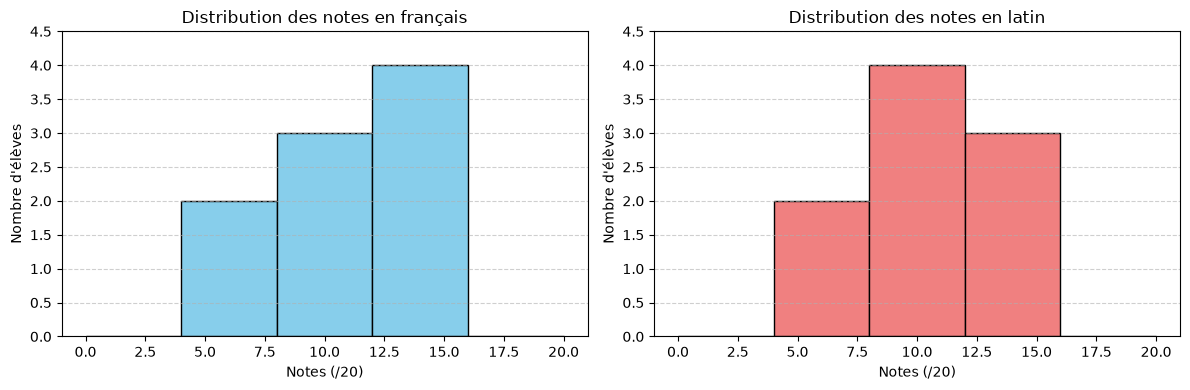

Moyenne en français : 10.22
Écart-type en français (population, ddof=0) : 3.47
Moyenne en latin : 10.06
Écart-type en latin (population, ddof=0) : 2.81


In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Histogramme pour le français
ax1.hist(X["fran"], bins=5, range=(0, 20), edgecolor="black", color="skyblue")
ax1.set_title("Distribution des notes en français")
ax1.set_xlabel("Notes (/20)")
ax1.set_ylabel("Nombre d'élèves")
ax1.set_ylim(0, 4.5)
ax1.grid(axis="y", linestyle="--", alpha=0.6)

# Histogramme pour le latin
ax2.hist(X["lati"], bins=5, range=(0, 20), edgecolor="black", color="lightcoral")
ax2.set_title("Distribution des notes en latin")
ax2.set_xlabel("Notes (/20)")
ax2.set_ylabel("Nombre d'élèves")
ax2.set_ylim(0, 4.5)
ax2.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

print("Moyenne en français :", round(X["fran"].mean(), 2))
print("Écart-type en français (population, ddof=0) :", round(X["fran"].std(ddof=0), 2))
print("Moyenne en latin :", round(X["lati"].mean(), 2))
print("Écart-type en latin (population, ddof=0) :", round(X["lati"].std(ddof=0), 2))

### Histogramme des notes de français — Commentaire

Les notes sont étalées de 5 à 15,5, avec davantage d’élèves dans les classes supérieures que dans les classes basses, mais sans concentration unique très nette. La moyenne est **10,22/20** et l’écart-type (calculé sur les 9 élèves, avec `ddof=0`) est **3,47 points** : la dispersion est donc notable, ce qui confirme la lecture de l’histogramme.

### Histogramme des notes de latin — Commentaire

Les notes s’étendent de 5,5 à 15 ; elles sont surtout regroupées entre 8 et 15, avec peu de valeurs dans la partie basse. La moyenne vaut **10,06/20** et l’écart-type **2,81 points** (`ddof=0`). La dispersion est un peu moins forte qu’en français, conformément à l’histogramme.

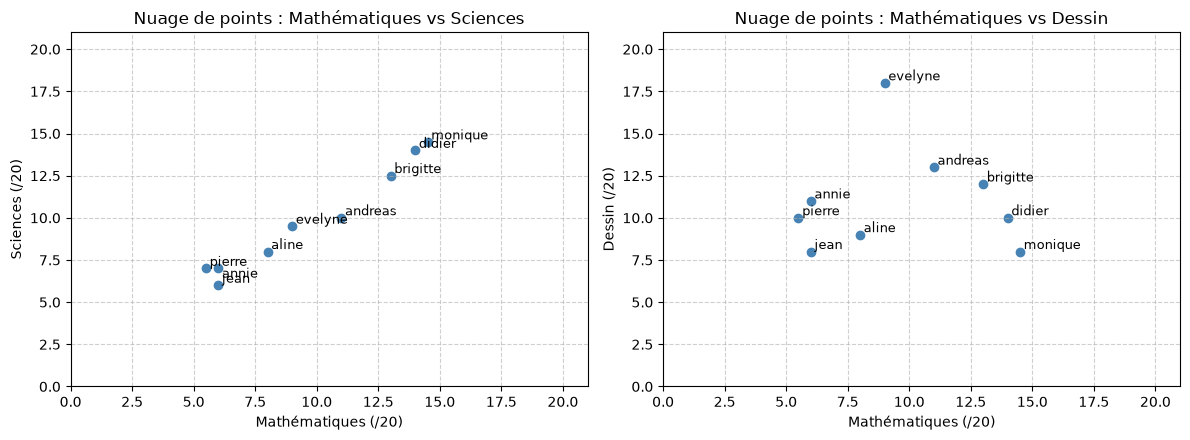

Corrélation linéaire mathématiques / sciences : 0.983
Corrélation linéaire mathématiques / dessin : 0.011


In [3]:
Data1 = X[["math", "scie"]].values
Data2 = X[["math", "d-m "]].values
n = len(nomi)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# --- Nuage 1 : Mathématiques vs Sciences ---
for i in range(0, n):
    ax1.scatter(Data1[i, 0], Data1[i, 1], color="steelblue")
    # Légère correction verticale pour éviter que 'annie' et 'pierre' ne se chevauchent
    dy = -0.55 if nomi[i] == "annie" else 0.15
    ax1.text(Data1[i, 0] + 0.15, Data1[i, 1] + dy, nomi[i], fontsize=9)

ax1.set_title("Nuage de points : Mathématiques vs Sciences")
ax1.set_xlabel("Mathématiques (/20)")
ax1.set_ylabel("Sciences (/20)")
ax1.set_xlim(0, 21)
ax1.set_ylim(0, 21)
ax1.grid(True, linestyle="--", alpha=0.6)

# --- Nuage 2 : Mathématiques vs Dessin ---
for i in range(0, n):
    ax2.scatter(Data2[i, 0], Data2[i, 1], color="steelblue")
    ax2.text(Data2[i, 0] + 0.15, Data2[i, 1] + 0.15, nomi[i], fontsize=9)

ax2.set_title("Nuage de points : Mathématiques vs Dessin")
ax2.set_xlabel("Mathématiques (/20)")
ax2.set_ylabel("Dessin (/20)")
ax2.set_xlim(0, 21)
ax2.set_ylim(0, 21)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

print("Corrélation linéaire mathématiques / sciences :", round(X["math"].corr(X["scie"]), 3))
print("Corrélation linéaire mathématiques / dessin :", round(X["math"].corr(X["d-m "]), 3))

### Nuage mathématiques–sciences — Commentaire

Les élèves sont presque alignés sur une diagonale croissante : ceux qui ont une note élevée en mathématiques ont généralement aussi une note élevée en sciences. Le coefficient de corrélation de Pearson est **$r=0,983$**, très proche de 1 ; il confirme une association linéaire positive très forte.

### Nuage mathématiques–dessin — Commentaire

Le nuage ne présente pas d’alignement linéaire discernable : les notes de dessin varient sans suivre régulièrement les notes de mathématiques. Le coefficient **$r=0,011$** est pratiquement nul ; il confirme l’absence de relation linéaire dans cet échantillon (sans exclure toute forme de relation non linéaire).

## 1.2 Calcul de l’ACP

In [4]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

# Chargement et transposition (individus en lignes, variables en colonnes)
X = np.transpose(pd.read_csv("notes.csv", sep=";", index_col=0))

# Récupération des noms (attention : les commentaires de l'énoncé sont inversés)
nomi = list(X.index)    # noms des individus (les 9 élèves)
nomv = list(X.columns)  # noms des variables (les 5 matières)

# Nombre de variables (p = 5)
p = X.shape[1]

# Initialisation et calcul de l'ACP (sur données centrées uniquement)
acp = PCA(n_components=p, random_state=42)
cc = acp.fit_transform(X)  # Coordonnées des 9 élèves sur les 5 axes principaux

# Affichage des valeurs propres (inertie de chaque axe)
print("Valeurs propres (variance expliquée) :", acp.explained_variance_.round(2))
print("Pourcentage d'inertie expliquée :", (acp.explained_variance_ratio_ * 100).round(2))

# Affichage des axes principaux (vecteurs propres en lignes)
axes = pd.DataFrame(acp.components_, columns=nomv, index=[f"Axe {i+1}" for i in range(p)])
print("\nVecteurs propres (axes principaux) :")
print(axes.round(3))

Valeurs propres (variance expliquée) : [3.178e+01 1.358e+01 9.690e+00 2.000e-02 1.000e-02]
Pourcentage d'inertie expliquée : [5.769e+01 2.465e+01 1.759e+01 4.000e-02 2.000e-02]

Vecteurs propres (axes principaux) :
        math   scie   fran   lati   d-m 
Axe 1  0.515  0.507  0.492  0.485  0.031
Axe 2 -0.567 -0.372  0.650  0.323  0.113
Axe 3  0.051  0.014 -0.108 -0.023  0.992
Axe 4  0.289 -0.553 -0.394  0.674 -0.034
Axe 5  0.573 -0.546  0.410 -0.453  0.013


### Commentaire des résultats

Les valeurs propres (variances des composantes, calculées sur les données centrées) sont environ **31,78 ; 13,58 ; 9,69 ; 0,024 ; 0,011**. Elles correspondent respectivement à **57,69 % ; 24,65 % ; 17,59 % ; 0,044 % ; 0,020 %** de l’inertie totale. Les deux premiers axes résument donc déjà l’essentiel de la structure.

Le premier vecteur propre donne des poids positifs proches pour les quatre matières scolaires (mathématiques, sciences, français et latin), et presque nul pour le dessin : il traduit un niveau scolaire général. Le deuxième oppose principalement les mathématiques/sciences (coefficients négatifs) au français/latin (positifs), tandis que le troisième est presque entièrement porté par le dessin (coefficient voisin de 0,992). Le signe global d’un vecteur propre est arbitraire : c’est l’opposition des signes au sein d’un axe qui s’interprète.

## 1.3 Représentation

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from affichage_acp import my_biplot

# Chargement et transposition (individus en lignes, variables en colonnes)
X = np.transpose(pd.read_csv("notes.csv", sep=";", index_col=0))

# Récupération des noms (attention : les commentaires de l'énoncé sont inversés)
nomi = list(X.index)    # noms des individus (les 9 élèves)
nomv = list(X.columns)  # noms des variables (les 5 matières)

# Nombre de variables (p = 5)
p = X.shape[1]

# Initialisation et calcul de l'ACP (sur données centrées uniquement)
acp = PCA(n_components=p, random_state=42)

cc = acp.fit_transform(X)

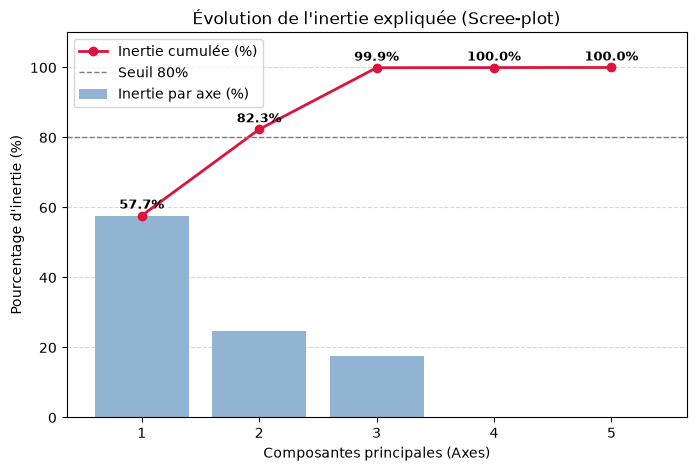

In [6]:
# Pourcentage d'inertie expliquée et inertie cumulée
inertie_pct = acp.explained_variance_ratio_ * 100
inertie_cum = np.cumsum(inertie_pct)
axes_num = np.arange(1, p + 1)

plt.figure(figsize=(8, 5))
plt.bar(axes_num, inertie_pct, alpha=0.6, color="steelblue", label="Inertie par axe (%)")
plt.plot(axes_num, inertie_cum, marker="o", color="crimson", linewidth=2, label="Inertie cumulée (%)")

# Affichage des pourcentages au-dessus des points
for i, txt in enumerate(inertie_cum):
    plt.annotate(f"{txt:.1f}%", (axes_num[i], inertie_cum[i] + 2), ha="center", fontsize=9, fontweight="bold")

plt.axhline(80, color="gray", linestyle="--", linewidth=1, label="Seuil 80%")
plt.title("Évolution de l'inertie expliquée (Scree-plot)")
plt.xlabel("Composantes principales (Axes)")
plt.ylabel("Pourcentage d'inertie (%)")
plt.xticks(axes_num)
plt.ylim(0, 110)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)



### Scree-plot et choix du nombre d’axes

**Pour dépasser le seuil de 80 %, deux axes suffisent** : ils cumulent **82,34 %** de l’inertie. C’est le choix parcimonieux pour une représentation synthétique. En revanche, **trois axes** sont préférables si l’on veut intégrer explicitement la dimension artistique : ils cumulent **99,93 %** et l’axe 3 est presque entièrement associé au dessin. Les axes 4 et 5 n’ajoutent ensemble qu’environ **0,07 %**.

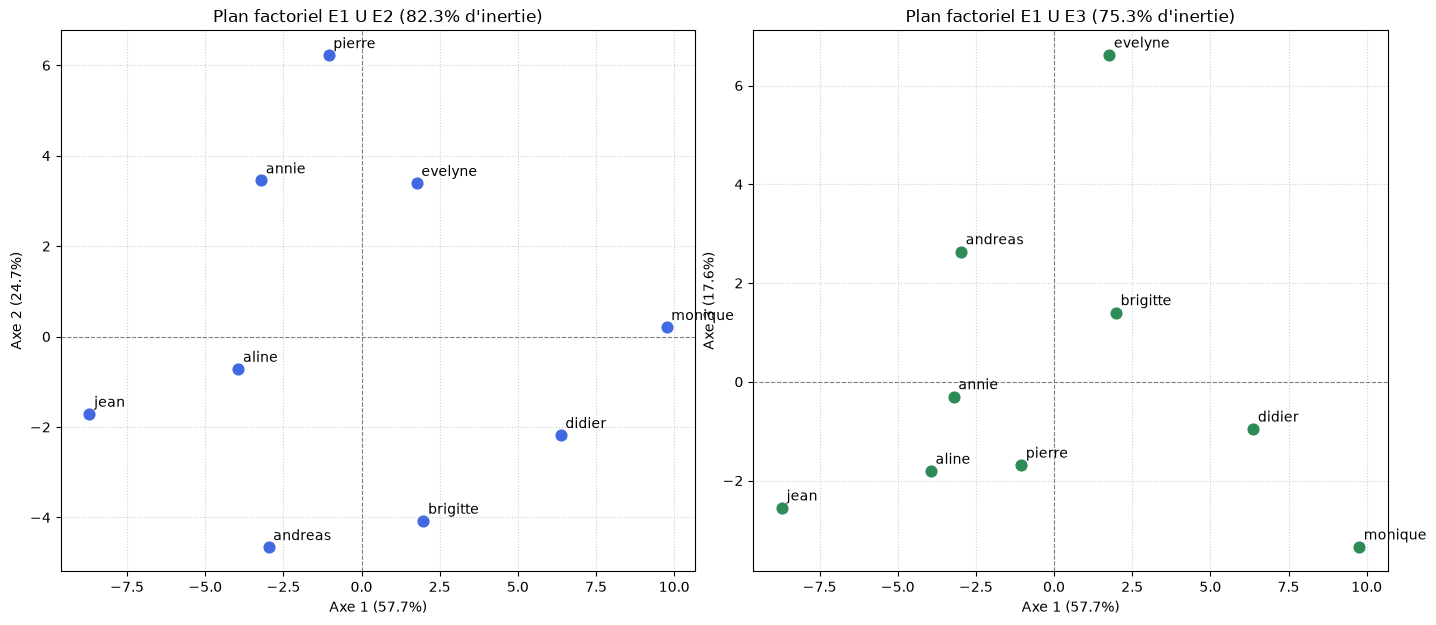

In [7]:
# Partie 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

fig.tight_layout()

# --- Plan E1 U E2 (Axes 1 et 2) ---
ax1.scatter(cc[:, 0], cc[:, 1], color="royalblue", s=60)
for i in range(len(nomi)):
    ax1.text(cc[i, 0] + 0.15, cc[i, 1] + 0.15, nomi[i], fontsize=10)
ax1.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax1.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax1.set_title(f"Plan factoriel E1 U E2 ({inertie_pct[0]+inertie_pct[1]:.1f}% d'inertie)")
ax1.set_xlabel(f"Axe 1 ({inertie_pct[0]:.1f}%)")
ax1.set_ylabel(f"Axe 2 ({inertie_pct[1]:.1f}%)")
ax1.grid(True, linestyle=":", alpha=0.6)

# --- Plan E1 U E3 (Axes 1 et 3) ---
ax2.scatter(cc[:, 0], cc[:, 2], color="seagreen", s=60)
for i in range(len(nomi)):
    ax2.text(cc[i, 0] + 0.15, cc[i, 2] + 0.15, nomi[i], fontsize=10)
ax2.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax2.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax2.set_title(f"Plan factoriel E1 U E3 ({inertie_pct[0]+inertie_pct[2]:.1f}% d'inertie)")
ax2.set_xlabel(f"Axe 1 ({inertie_pct[0]:.1f}%)")
ax2.set_ylabel(f"Axe 3 ({inertie_pct[2]:.1f}%)")
ax2.grid(True, linestyle=":", alpha=0.6)



### Individus dans le plan $E_1 \cup E_2$

L’axe 1 sépare les élèves au niveau scolaire global élevé, à droite (notamment **Monique** et **Didier**), des élèves aux notes globalement plus faibles, à gauche (en particulier **Jean** et **Aline**). Sur l’axe 2, **Annie** et **Pierre** se distinguent du côté littéraire, tandis qu’**Andreas** et **Brigitte** se situent du côté scientifique. **Évelyne** est plutôt du côté littéraire et possède un niveau global intermédiaire. Ce plan rend donc visible à la fois un gradient de niveau et une opposition de profils.

### Individus dans le plan $E_1 \cup E_3$

L’axe 1 conserve le gradient de niveau général. L’axe 3 isole surtout **Évelyne**, qui a la note de dessin la plus élevée, et dans une moindre mesure **Andreas** et **Brigitte**, également au-dessus de plusieurs autres élèves en dessin. **Monique** et **Didier** se caractérisent surtout par leurs fortes notes scolaires générales plutôt que par une position extrême sur cet axe. Ce second plan fait ainsi ressortir la dimension artistique que le plan $(E_1,E_2)$ ne représente pas directement.

In [8]:
# Partie 3

# Variances initiales de chaque matière (ddof=1 comme dans PCA de sklearn)
var_init = X.var(axis=0, ddof=1).values      # taille (p,)
lambdas = acp.explained_variance_            # taille (p,)

# Calcul de la matrice des corrélations (variables en lignes, axes en colonnes)
corr_var_axes = np.zeros((p, p))
for k in range(p):      # indice variable (matière)
    for j in range(p):  # indice composante (axe)
        corr_var_axes[k, j] = acp.components_[j, k] * np.sqrt(lambdas[j] / var_init[k])

df_corr = pd.DataFrame(corr_var_axes, index=nomv, columns=[f"Axe {j+1}" for j in range(p)])
print("Corrélations entre variables initiales et composantes principales :")
print(df_corr[["Axe 1", "Axe 2", "Axe 3"]].round(3))



Corrélations entre variables initiales et composantes principales :
      Axe 1  Axe 2  Axe 3
math  0.810 -0.584  0.045
scie  0.901 -0.432  0.014
fran  0.754  0.651 -0.091
lati  0.916  0.399 -0.024
d-m   0.055  0.133  0.990


### Corrélations variables / composantes — Commentaire

- **Axe 1 — niveau général / effet taille :** les quatre matières scolaires sont positivement corrélées à l’axe (mathématiques **0,810**, sciences **0,901**, français **0,754**, latin **0,916**). Le dessin y est presque indépendant (**0,055**).
- **Axe 2 — opposition littéraire / scientifique :** le français (**0,651**) et le latin (**0,399**) sont du côté positif, tandis que les mathématiques (**−0,584**) et les sciences (**−0,432**) sont du côté négatif. Le dessin contribue peu (**0,133**).
- **Axe 3 — axe artistique :** le dessin est très fortement corrélé à cet axe (**0,990**), alors que les quatre matières scolaires ont des corrélations proches de zéro.

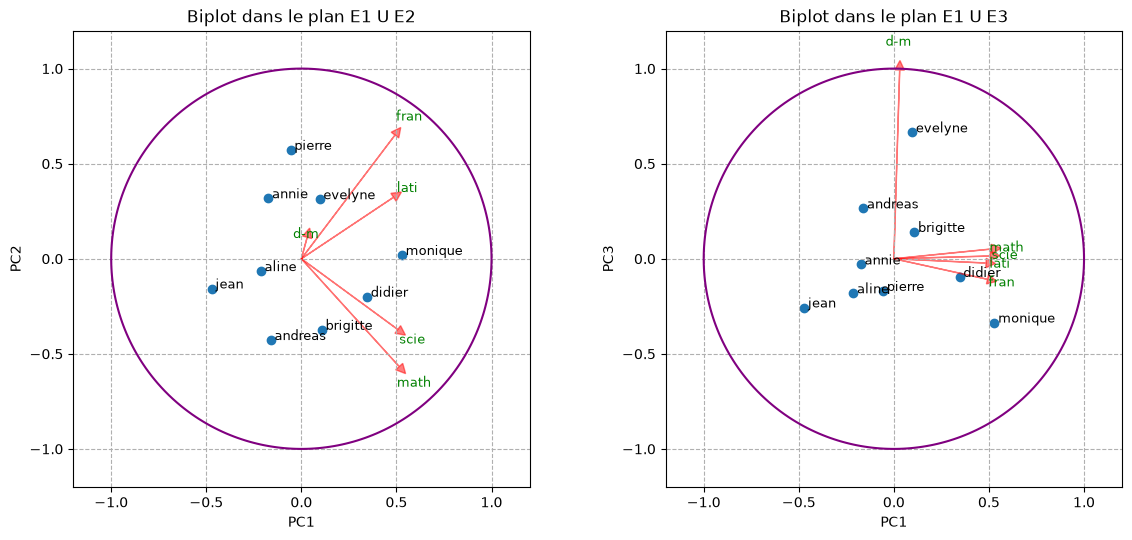

In [9]:
# Partie 4 : Les deux biplots côte à côte sur une seule figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5))

# Biplot dans le plan E1 U E2 (Axes 1 et 2)
my_biplot(
    score=cc[:, 0:2],
    coeff=np.transpose(acp.components_[0:2, :]),
    coeff_labels=nomv,
    score_labels=nomi,
    nomx="PC1",
    nomy="PC2",
    titre="Biplot dans le plan E1 U E2",
    ax=ax1
)

# Biplot dans le plan E1 U E3 (Axes 1 et 3)
my_biplot(
    score=cc[:, [0, 2]],
    coeff=np.transpose(acp.components_[[0, 2], :]),
    coeff_labels=nomv,
    score_labels=nomi,
    nomx="PC1",
    nomy="PC3",
    titre="Biplot dans le plan E1 U E3",
    ax=ax2
)

plt.tight_layout()
plt.show()

### Biplots $(E_1,E_2)$ et $(E_1,E_3)$ — Analyse des résultats

Les biplots croisent les positions des élèves et les directions des vecteurs matières : un élève projeté dans la direction d’une matière tend à avoir une note élevée dans celle-ci. Dans le plan $(E_1,E_2)$, les vecteurs mathématiques/sciences et français/latin pointent dans des directions opposées sur l’axe 2, ce qui confirme les **modes de fonctionnement scientifiques et littéraires**. **Monique** et **Didier** se distinguent par leur niveau élevé dans les matières scolaires ; **Annie** et **Pierre** se rapprochent du pôle littéraire ; **Brigitte** et, dans une moindre mesure, **Andreas**, du pôle scientifique. **Jean** et **Aline** forment des profils en difficulté au regard de leurs notes globalement basses. Les élèves proches du centre ont des profils moins tranchés ou intermédiaires.

Dans le plan $(E_1,E_3)$, la direction du dessin est presque celle de l’axe 3 : **Évelyne**, puis **Andreas** et **Brigitte**, se distinguent davantage par leurs notes de dessin. Les biplots suggèrent donc des classes descriptives — bons résultats scolaires, tendances scientifiques ou littéraires, profils intermédiaires, élèves en difficulté et profils artistiques — mais **ne constituent pas une classification formelle** : l’ACP décrit des proximités et des oppositions, elle n’affecte pas elle-même les élèves à des groupes.

## Regard critique et limites méthodologiques

- **Très petit effectif :** avec seulement $n=9$ élèves, les résultats sont exploratoires et sensibles à chaque individu. Un point extrême peut déplacer les axes et modifier les interprétations.
- **ACP non normée :** l’analyse est effectuée sur la matrice de covariance des notes centrées, sans réduction à variance unitaire. Comme toutes les notes sont sur la même échelle (sur 20), ce choix est défendable ; toutefois, les matières ayant une variance plus forte pèsent davantage dans les axes. Une ACP normée basée sur la matrice de corrélation pourrait conduire à une représentation différente.
- **Inertie résiduelle presque nulle :** les matières scolaires présentent une structure largement résumée par deux dimensions (niveau global et opposition scientifique/littéraire), et le dessin forme presque à lui seul une troisième dimension. Il reste seulement **0,07 %** d’inertie sur les axes 4 et 5 réunis. Cette quasi-redondance de l’information dans les matières scolaires explique que ces deux derniers axes apportent très peu, plutôt qu’une indépendance totale des variables.

## Conclusion — Exercice 1

L’ACP a résumé les notes des neuf élèves en trois dimensions interprétables : le niveau scolaire général, l’opposition entre tendances scientifiques et littéraires, puis une dimension essentiellement artistique portée par le dessin. Deux axes suffisent à dépasser 80 % de l’inertie, tandis que le troisième est utile pour intégrer cette matière atypique. Les représentations distinguent des profils contrastés et des élèves aux résultats proches, mais, compte tenu du très faible effectif, ces regroupements doivent rester descriptifs et prudents.